<div align="left" style="background-color: #008080; padding: 20px 10px;">
<h3><b style="color: white;">IDEAS - Institute of Data Engineering, Analytics and Science Foundation</b></h3>
<p style="color: white;">Autumn Internship Program 2026</p>
<hr style="width:75%; background-color: white; border-color: white;">
<h3 style="color: white;">Project Title: News Article Authentication and Fraud Detection</h3>
<h4 style="color: white;">Mentor Name: Dr. Chandan Biswas</h4>
</div>

## Project Overview

The dissemination of fabricated news articles poses a significant risk to information integrity. The objective of this project is to build an end-to-end machine learning pipeline capable of authenticating news articles and classifying them as either real or fraudulent.

Students are expected to perform rigorous exploratory data analysis, data preparation, baseline modeling, unsupervised clustering, multi-layer perceptron implementation, and custom business metric evaluation. You are required to provide written analytical interpretations for specific outcomes to demonstrate conceptual understanding.

**Dataset Link:** [Fake and Real News Dataset (Kaggle)](https://www.kaggle.com/datasets/clmentbisaillon/fake-and-real-news-dataset)

---


### Question 1: Data Ingestion and Merging (5 Marks)

Load the `Fake.csv` and `True.csv` files into two separate pandas DataFrames. Create a new target column named `is_fake` in both DataFrames, assigning the value `1` for the fake news dataset and `0` for the true news dataset. Finally, concatenate them into a single DataFrame named `news_df` and shuffle the rows.

**Hint:** Utilize standard data ingestion functions for CSV files. Assign the new binary column before concatenating the structures. Ensure the final index is reset or the data is thoroughly randomized to avoid grouped target variables.

**Expected Output:** A single, shuffled pandas DataFrame containing all records from both original files, including the newly instantiated binary indicator column.

In [ ]:
import pandas as pd
fake_df=pd.read_csv('Fake.csv')
true_df=pd.read_csv('True.csv')
fake_df['is_fake']=1
true_df['is_fake']=0
news_df=pd.concat([fake_df,true_df])
news_df=news_df.sample(frac=1,random_state=42).reset_index(drop=True)
print("Shape of news_df:",news_df.shape)
print(news_df.head())

Shape of news_df: (44898, 5)
                                               title  \
0  Ben Stein Calls Out 9th Circuit Court: Committ...   
1  Trump drops Steve Bannon from National Securit...   
2  Puerto Rico expects U.S. to lift Jones Act shi...   
3   OOPS: Trump Just Accidentally Confirmed He Le...   
4  Donald Trump heads for Scotland to reopen a go...   

                                                text       subject  \
0  21st Century Wire says Ben Stein, reputable pr...       US_News   
1  WASHINGTON (Reuters) - U.S. President Donald T...  politicsNews   
2  (Reuters) - Puerto Rico Governor Ricardo Rosse...  politicsNews   
3  On Monday, Donald Trump once again embarrassed...          News   
4  GLASGOW, Scotland (Reuters) - Most U.S. presid...  politicsNews   

                  date  is_fake  
0    February 13, 2017        1  
1       April 5, 2017         0  
2  September 27, 2017         0  
3         May 22, 2017        1  
4       June 24, 2016         0  


### Question 2: Exploratory Data Analysis & Balancing (6 Marks)

Verify the structural integrity of the combined dataset. Check for and drop any missing values across all columns. Calculate and display the percentage distribution of the `is_fake` target variable. Finally, provide a brief written analysis of whether this dataset exhibits class imbalance and how that impacts the choice of evaluation metrics for upcoming classification models.

**Hint:** Examine the proportion of each class in the target variable. Print your written answer using Python `print()` statements, addressing accuracy vs. metrics like F1-score in imbalanced scenarios.

**Expected Output:** A printed display showing the proportional percentage of real versus fake articles, followed by a printed textual explanation regarding class balance and metric selection.

In [ ]:
print(news_df.isnull().sum())
news_df =news_df.dropna()
print("Shape after dropping missing values:",news_df.shape)
percent =news_df['is_fake'].value_counts(normalize=True)*100
print("\nPercentage distribution (0 = real,1 = fake):")
print(percent)
print("\nThe dataset is almost balanced,there are only slightly more fake articles than real ones,so there is no serious class imbalance.")
print("Because of this,accuracy is a fairly reliable metric here.")
print("But if the data was imbalanced,accuracy would be misleading because a model that always predicts the big class would still get a high score.")
print("In that case F1-score is better since it uses both precision and recall.So we will use F1-score along with accuracy.")

title      0
text       0
subject    0
date       0
is_fake    0
dtype: int64
Shape after dropping missing values: (44898, 5)

Percentage distribution (0 = real,1 = fake):
is_fake
1    52.298543
0    47.701457
Name: proportion, dtype: float64

The dataset is almost balanced,there are only slightly more fake articles than real ones,so there is no serious class imbalance.
Because of this,accuracy is a fairly reliable metric here.
But if the data was imbalanced,accuracy would be misleading because a model that always predicts the big class would still get a high score.
In that case F1-score is better since it uses both precision and recall.So we will use F1-score along with accuracy.


### Question 3: Text Cleaning and Preprocessing Pipeline (8 Marks)

Construct a Python function named `clean_text` that processes an input string by converting it to lowercase, removing all URLs, and stripping out all punctuation marks. Apply this function efficiently to the `text` column of `news_df` and store the result in a new column called `clean_text`.

**Hint:** Utilize regular expressions to identify standard URL patterns and punctuation boundaries. Ensure the application method operates efficiently across a large pandas Series without explicit looping.

**Expected Output:** The DataFrame will contain a new column where the article text is strictly lowercase, completely devoid of web links, and stripped of punctuation marks.

In [ ]:
import re
def clean_text(text):
    text =text.lower()
    text =re.sub(r'http\S+|www\.\S+','',text)
    text =re.sub(r'[^\w\s]','',text)
    return text
news_df['clean_text'] =news_df['text'].apply(clean_text)
print(news_df['clean_text'].head(3))

0    21st century wire says ben stein reputable pro...
1    washington reuters  us president donald trump ...
2    reuters  puerto rico governor ricardo rossello...
Name: clean_text, dtype: object


### Question 4: Outlier Detection via Text Length Analysis (7 Marks)

Unusually long or short texts can skew model training. Calculate the word count for each article in the `clean_text` column. Identify the 99th percentile of word counts. Filter the DataFrame to remove any articles whose word count strictly exceeds this 99th percentile threshold.

**Hint:** Calculate the word count by splitting the text by whitespace. Compute the statistical threshold for the 99th percentile, and subset the DataFrame to retain only observations below or equal to this limit.

**Expected Output:** A reduced pandas DataFrame with extreme text length outliers removed, along with a printed numerical integer representing the calculated 99th percentile word count threshold.

In [ ]:
news_df['word_count'] =news_df['clean_text'].apply(lambda x:len(x.split()))
limit =news_df['word_count'].quantile(0.99)
print("99th percentile word count:",int(limit))
news_df =news_df[news_df['word_count']<=limit]
print("Shape after removing outliers:",news_df.shape)

99th percentile word count: 1508
Shape after removing outliers: (44450, 7)


### Question 5: Text Vectorization using TF-IDF (6 Marks)

Separate the dataset into features (`X = clean_text`) and target (`y = is_fake`). Split the data into training (80%) and testing (20%) sets. Initialize a Term Frequency-Inverse Document Frequency (TF-IDF) vectorizer with a maximum of 5000 features. Fit the vectorizer on the training data and transform both sets. Print a brief explanation of why TF-IDF is generally preferred over standard bag-of-words (count vectorization) for text classification.

**Hint:** Segregate the data prior to fitting to prevent data leakage. Print your written answer using Python `print()` statements, focusing on how TF-IDF handles frequent, uninformative words.

**Expected Output:** Two sparse numerical matrices representing the weighted word frequencies of the training and testing datasets, accompanied by a printed analytical text explaining the conceptual advantage of TF-IDF.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
X =news_df['clean_text']
y =news_df['is_fake']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
tfidf =TfidfVectorizer(max_features=5000)
X_train_vec =tfidf.fit_transform(X_train)
X_test_vec =tfidf.transform(X_test)
print("Training matrix:")
print(X_train_vec)
print("Shape:",X_train_vec.shape)
print("\nTesting matrix:")
print(X_test_vec)
print("Shape:",X_test_vec.shape)
print("\nTF-IDF is better than normal bag of words (count vectorizer) because it gives less weight to words that come in almost every article like 'the','is','and' which do not tell us anything.")
print("It gives more weight to words that are important in an article but rare in other articles,so the model can learn from useful words.")

Training matrix:
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 5895850 stored elements and shape (35560, 5000)>
  Coords	Values
  (0, 1960)	0.16639511516568384
  (0, 3836)	0.050217100048797175
  (0, 4501)	0.27031332316176937
  (0, 2110)	0.10084358900371797
  (0, 3106)	0.09314801241841374
  (0, 4680)	0.23594001403632883
  (0, 2905)	0.278320061410915
  (0, 4792)	0.10859516941380308
  (0, 2278)	0.12552068073580538
  (0, 2980)	0.33224783683982295
  (0, 3609)	0.1790448814817527
  (0, 4262)	0.06438842395543413
  (0, 3932)	0.0385951895657461
  (0, 3131)	0.06370954309593989
  (0, 4650)	0.08167526483954776
  (0, 2109)	0.04155708179467679
  (0, 2412)	0.10609496895618777
  (0, 4289)	0.08182466783105714
  (0, 4824)	0.14701655410751321
  (0, 1864)	0.03449350942575802
  (0, 3307)	0.16639511516568384
  (0, 4561)	0.1228819469317098
  (0, 1592)	0.1465530556334662
  (0, 1141)	0.14254200612010262
  (0, 4860)	0.10089528725817057
  :	:
  (35559, 4107)	0.05660733119463573
  (35559, 3209)	0.1

### Question 6: Baseline Supervised Model: Logistic Regression (6 Marks)

Instantiate and train a Logistic Regression classifier on the TF-IDF training vectors. Predict the target values for the test set. Calculate and print the F1-score to establish a baseline performance metric for future comparisons.

**Hint:** Utilize the standard implementation for linear classification. Ensure you import the appropriate evaluation metric function to measure the harmonic mean of precision and recall.

**Expected Output:** A single float value displayed on the screen representing the calculated F1-score for the baseline classification model.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
lr_model =LogisticRegression()
lr_model.fit(X_train_vec,y_train)
lr_pred =lr_model.predict(X_test_vec)
print("Baseline F1-score:",f1_score(y_test,lr_pred))

Baseline F1-score: 0.9890324682375936


### Question 7: Unsupervised Learning: K-Means Clustering (7 Marks)

Investigate if natural groupings in the text data inherently align with the fake/real news dichotomy. Apply the K-Means clustering algorithm to the TF-IDF training vectors, specifying exactly 2 clusters. Calculate the Adjusted Rand Index (ARI) comparing the generated cluster labels against the true `y_train` labels. Print a brief interpretation of what the ARI score indicates about the textual similarity of the classes.

**Hint:** Extract the generated cluster arrays after fitting the unsupervised model. Print your written answer using Python `print()` statements, analyzing whether the natural groupings correlate strongly with the actual target labels based on the ARI magnitude.

**Expected Output:** A calculated float value between -1.0 and 1.0 representing the ARI, followed by a printed analytical paragraph interpreting the result in the context of the dataset.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
kmeans =KMeans(n_clusters=2,random_state=42)
clusters =kmeans.fit_predict(X_train_vec)
ari =adjusted_rand_score(y_train,clusters)
print("ARI score:",ari)
if ari<0.1:
    print("The ARI is close to 0,so the clusters made by K-Means are not related to the fake/real labels.The text of fake and real news is not naturally separated in two groups.")
elif ari < 0.5:
    print("The ARI is moderate,so the clusters match the fake/real labels only a little.K-Means finds some groups but they are not the same as fake and real news.")
else:
    print("The ARI is high,so the two clusters match the fake/real labels well.Fake and real news are written in different ways.")

ARI score: 0.02576546687740215
The ARI is close to 0,so the clusters made by K-Means are not related to the fake/real labels.The text of fake and real news is not naturally separated in two groups.


### Question 8: Dimensionality Reduction: TruncatedSVD for Visualization (7 Marks)

To visually analyze the feature space, reduce the dimensionality of the TF-IDF training vectors to exactly 2 components using Truncated Singular Value Decomposition (SVD). Generate a 2D scatter plot of these components, coloring the points according to their true class labels (`is_fake`).

**Hint:** Dimensionality reduction compresses thousands of word features into two principal axes, allowing humans to visually inspect if real and fake news form distinct geometric clusters. Map the reduced components to the x and y axes of a scatter plot.

**Expected Output:** A two-dimensional scatter plot graphic visualizing the spatial distribution and separability of real versus fake news articles based on their reduced textual features.

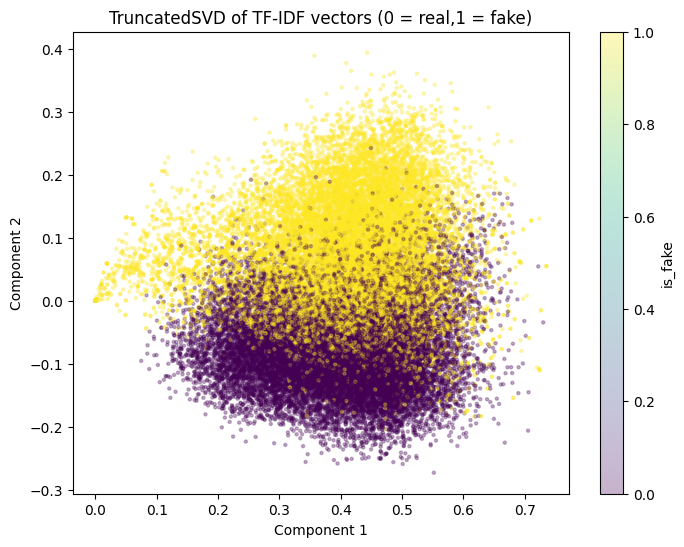

In [ ]:
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD
svd =TruncatedSVD(n_components=2,random_state=42)
reduced =svd.fit_transform(X_train_vec)
plt.figure(figsize=(8,6))
plt.scatter(reduced[:,0],reduced[:,1],c=y_train,alpha=0.3,s=5)
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.title("TruncatedSVD of TF-IDF vectors (0 = real,1 = fake)")
plt.colorbar(label="is_fake")
plt.show()

### Question 9: Feature Engineering: Sentiment Polarity (8 Marks)

Research suggests fabricated news frequently relies on polarized language; therefore, extracting sentiment polarity may yield predictive features. Select the first 1000 rows of your cleaned DataFrame. Calculate a sentiment polarity score for each article's text using a library like TextBlob or VADER. Add these scores as a new column named `sentiment_score` to this subset.

**Hint:** Do not write explicit `for` loops, as iterating over pandas rows is an anti-pattern. Instead, utilize vectorized operations or the pandas `.apply()` method in conjunction with the sentiment extraction function.

**Expected Output:** A sliced pandas DataFrame containing exactly 1000 rows with an appended numerical column representing the calculated emotional sentiment metric of the text.

In [ ]:
from textblob import TextBlob
sub_df =news_df.head(1000).copy()
sub_df['sentiment_score'] =sub_df['clean_text'].apply(lambda x:TextBlob(x).sentiment.polarity)
print("Shape:",sub_df.shape)
print(sub_df[['clean_text','sentiment_score']].head())

Shape: (1000, 8)
                                          clean_text  sentiment_score
0  21st century wire says ben stein reputable pro...         0.083333
1  washington reuters  us president donald trump ...         0.086597
2  reuters  puerto rico governor ricardo rossello...        -0.005044
3  on monday donald trump once again embarrassed ...        -0.011161
4  glasgow scotland reuters  most us presidential...         0.039347


### Question 10: Cross-Validation Strategy (6 Marks)

A single train-test split can be unreliable due to variance. Initialize a Random Forest Classifier. Execute a 5-fold cross-validation procedure on the training data (TF-IDF vectors and labels). Compute and print the mean accuracy across all 5 folds.

**Hint:** Implement the cross-validation function provided by model selection libraries. Aggregate the resulting array to find the central tendency of the model's accuracy across different data splits.

**Expected Output:** A single float value indicating the mean classification accuracy over five independent training and validation folds.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
rf =RandomForestClassifier(n_estimators=50,random_state=42)
scores =cross_val_score(rf,X_train_vec,y_train,cv=5)
print("Scores of each fold:",scores)
print("Mean accuracy:",scores.mean())

Scores of each fold: [0.99746907 0.99718785 0.99732846 0.99775028 0.99662542]
Mean accuracy: 0.9972722159730034


### Question 11: Multi-Layer Perceptron (MLP) Implementation (10 Marks)

Construct a neural network to model non-linear relationships in the text data. Initialize an `MLPClassifier` with a single hidden layer of 100 neurons, ReLU activation function, and the Adam optimizer. To prevent computational bottlenecks on standard hardware, train this model using only the first 5000 samples of your TF-IDF training vectors. Predict on the first 1000 samples of the test set and print the accuracy.

**Hint:** Neural networks learn by passing data through layers of interconnected nodes, allowing the model to capture complex relationships in the text that simple regression might miss. Ensure you slice both the feature matrix and target array consistently before fitting.

**Expected Output:** A printed float value denoting the accuracy of the multi-layer perceptron neural network on the unseen subset of test data.

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
mlp =MLPClassifier(hidden_layer_sizes=(100,),activation='relu',solver='adam',random_state=42)
mlp.fit(X_train_vec[:5000],y_train[:5000])
mlp_pred =mlp.predict(X_test_vec[:1000])
print("MLP accuracy:",accuracy_score(y_test[:1000],mlp_pred))

MLP accuracy: 0.98


### Question 12: Hyperparameter Optimization for MLP (7 Marks)

Optimize the neural network's configuration. Define a parameter grid varying the `learning_rate_init` (e.g., [0.001, 0.01]) and `batch_size` (e.g., [32, 64]). Use randomized search with 3 iterations to find the optimal combination for the MLP model. Execute this search on a subset of 2000 training samples to strictly manage execution time.

**Hint:** Define the dictionary of parameters to explore. Pass the initialized MLP, parameter dictionary, and iteration count to the appropriate search object before fitting on the subset.

**Expected Output:** A printed Python dictionary detailing the most effective learning rate and batch size combination found during the random search.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
param_grid = {
    'learning_rate_init': [0.001,0.01],
    'batch_size': [32,64]
}
mlp2 =MLPClassifier(hidden_layer_sizes=(100,),activation='relu',solver='adam',max_iter=20,random_state=42)
search=RandomizedSearchCV(mlp2,param_grid,n_iter=3,cv=3,random_state=42)
search.fit(X_train_vec[:2000],y_train[:2000])
print("Best parameters:",search.best_params_)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py

Best parameters: {'learning_rate_init': 0.01, 'batch_size': 32}


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


### Question 13: Confusion Matrix and Error Analysis (6 Marks)

Generate a confusion matrix based on the test set predictions from your trained MLP model (from Question 11). Visualize this matrix using a seaborn heatmap with annotations to clearly identify True Positives, True Negatives, False Positives, and False Negatives. Print a brief written assessment analyzing which type of error the model is more prone to making.

**Hint:** Extract the quantitative matrix and pass it to a heatmap plotting function. Print your written answer using Python `print()` statements, interpreting the numerical imbalances between the non-diagonal elements.

**Expected Output:** A color-coded 2x2 grid graphic showing the raw counts of correct and incorrect classifications, accompanied by a printed text analyzing the model's primary error tendency.

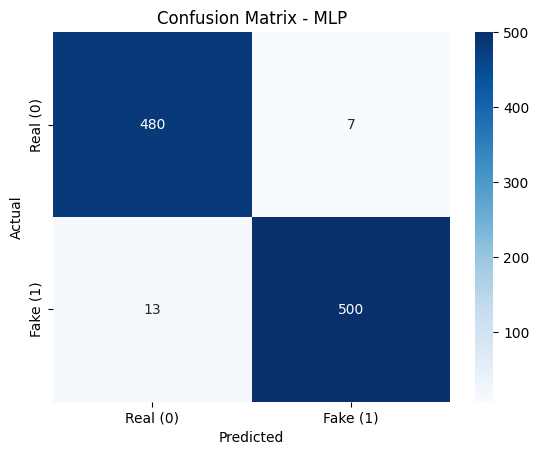

True Negatives: 480
False Positives: 7
False Negatives: 13
True Positives: 500
The model makes more False Negative errors,it calls some fake news as real news.


In [ ]:
import seaborn as sns
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test[:1000], mlp_pred)
tn,fp,fn,tp= cm.ravel()
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',
            xticklabels=['Real (0)','Fake (1)'],
            yticklabels=['Real (0)','Fake (1)'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - MLP")
plt.show()
print("True Negatives:",tn)
print("False Positives:",fp)
print("False Negatives:",fn)
print("True Positives:",tp)
if fn >fp:
    print("The model makes more False Negative errors,it calls some fake news as real news.")
elif fp>fn:
    print("The model makes more False Positive errors,it calls some real news as fake news.")
else:
    print("The model makes the same number of False Positive and False Negative errors.")

### Question 14: Custom Evaluation Metric: Business Cost Function (6 Marks)

In a production environment, allowing fabricated news to bypass filters (False Negative) is highly damaging to credibility, whereas occasionally flagging real news for manual review (False Positive) is merely inconvenient. Define a custom Python function calculating total business cost, assigning a penalty of 5 units for every False Negative and 1 unit for every False Positive. Compute the total penalty for your MLP model.

**Hint:** Extract the scalar values for False Positives and False Negatives from the flattened confusion matrix. Apply the respective multiplier weights and aggregate the total.

**Expected Output:** A single calculated integer printed to the console representing the total penalty cost based on the strict business logic constraints.

In [ ]:
def business_cost(fn,fp):
    return 5*fn+1*fp
total_cost =business_cost(fn,fp)
print("False Negatives:",fn)
print("False Positives:",fp)
print("Total business cost:",total_cost)

False Negatives: 13
False Positives: 7
Total business cost: 72


### Question 15: ROC Curve and Precision-Recall Analysis (5 Marks)

Evaluate the model's discriminative threshold capacity. Plot the Receiver Operating Characteristic (ROC) curve for the MLP model (using the 1000 test sample subset) and compute the Area Under the Curve (AUC) score. Display the ROC curve graphically and print the numeric AUC score.

**Hint:** Extract the prediction probabilities for the positive class rather than the absolute class labels. Utilize the false positive rate and true positive rate vectors to generate the visualization.

**Expected Output:** A plotted line graph demonstrating the tradeoff between sensitivity and specificity, accompanied by a printed float value representing the total calculated area under the curve.

AUC score: 0.9966977676909591


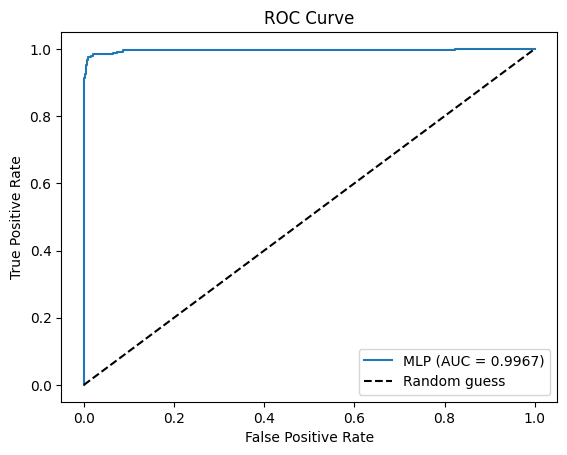

In [ ]:
from sklearn.metrics import roc_curve,roc_auc_score
probs =mlp.predict_proba(X_test_vec[:1000])[:,1]
fpr,tpr,thresholds= roc_curve(y_test[:1000],probs)
auc =roc_auc_score(y_test[:1000],probs)
print("AUC score:",auc)
plt.plot(fpr,tpr,label="MLP (AUC = %.4f)"%auc)
plt.plot([0,1],[0,1],'k--',label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()